# 13 店舗別売上変化の分解：来店・着席・客単価

全店舗の来店ログを全件集計する。**1日あたり売上 = 1日あたり来店組数 × 着席組率 × 着席1組あたり売上** という恒等式を使い、前年比や各月の変化を記述する。売上は値引き後。2024年は閏年なので、年・月とも日数で割って比較する。

これは観測値の算術分解であり、改装や価格、施策などの原因・効果を特定するものではない。来店・着席・会計は2024年までの実績で、2025年同日の特徴量には使えない。

In [1]:
from pathlib import Path
import zipfile,io,calendar as pycalendar
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input';sns.set_theme(style='whitegrid');pd.options.display.float_format='{:,.4f}'.format
stores=pd.read_csv(INPUT/'stores.csv')[['store_id','area_type']]
store_ids=stores.store_id.tolist()

## 来店ログの全件集計と売上照合
着席・離脱は組数。月ごとに暦日数で割り、2024年2月を含めて1日あたりで比較する。

In [2]:
parts=[];segments=[];sizes=[]
with zipfile.ZipFile(INPUT/'logs.zip') as z:
    for sid in store_ids:
        with z.open(f'logs/{sid}/visit_log.parquet') as f:
            v=pq.read_table(io.BytesIO(f.read()),columns=['store_id','date','group_id','group_size','segment','is_seated','is_left','net_sales_amount']).to_pandas()
        assert v.store_id.eq(sid).all()
        v['year']=v.date.dt.year;v['month']=v.date.dt.month
        metrics={'groups':('group_id','size'),'seated':('is_seated','sum'),'left':('is_left','sum'),'guests':('group_size','sum'),'net':('net_sales_amount','sum')}
        parts.append(v.groupby(['store_id','year','month'],observed=True).agg(**metrics).reset_index())
        segments.append(v.groupby(['store_id','year','month','segment'],observed=True).agg(**metrics).reset_index())
        sizes.append(v.groupby(['store_id','year','group_size'],observed=True).agg(**metrics).reset_index())
        print(sid,'来店組:',len(v),flush=True)
monthly=pd.concat(parts,ignore_index=True);segment=pd.concat(segments,ignore_index=True);sizes=pd.concat(sizes,ignore_index=True)
monthly['days']=[pycalendar.monthrange(y,m)[1] for y,m in zip(monthly.year,monthly.month)]
assert len(monthly)==10*3*12 and monthly.groups.sum()==2491880
assert monthly.groups.eq(monthly.seated+monthly.left).all()
print('集計行:',len(monthly),'来店組:',monthly.groups.sum(),'着席組:',monthly.seated.sum(),'離脱組:',monthly.left.sum())
sales=pd.read_csv(INPUT/'train.csv',parse_dates=['date']);sales['year']=sales.date.dt.year;sales['month']=sales.date.dt.month
sales_month=sales.groupby(['store_id','year','month'],as_index=False).sales_amount.sum()
check=monthly.merge(sales_month,on=['store_id','year','month'],validate='one_to_one')
print('月×店舗のログ・売上の不一致:',int((check.net-check.sales_amount).abs().gt(1e-6).sum()))
assert (check.net-check.sales_amount).abs().le(1e-6).all()

S001 来店組: 335479
S002 来店組: 308798
S003 来店組: 255933
S004 来店組: 285398
S005 来店組: 214109
S006 来店組: 162109
S007 来店組: 193307
S008 来店組: 227188
S009 来店組: 151785
S010 来店組: 357774
集計行: 360 来店組: 2491880 着席組: 2337482 離脱組: 154398
月×店舗のログ・売上の不一致: 0


## 年次の来店組数・着席率・着席組単価
年の日数により1日あたりに変換。組単価は着席組による売上÷着席組数。離脱組も来店組の分母に含める。

,store_id,area_type,year,groups_per_day,seat_rate,net_per_seated,net_per_day
0,S001,urban_core,2022,262.8932,0.8438,"2,485.8037","551,439.7918"
1,S001,urban_core,2023,320.0959,0.9103,"2,409.4303","702,088.1863"
2,S001,urban_core,2024,335.2131,0.9407,"2,550.5874","804,278.2568"
3,S002,office,2022,269.9370,0.9498,"2,177.9970","558,384.7315"
4,S002,office,2023,280.7671,0.9438,"2,149.1063","569,489.6192"
5,S002,office,2024,294.5109,0.9531,"2,212.7508","621,105.8579"
6,S003,suburban_sc,2022,223.3452,0.8880,"2,983.2006","591,670.8521"
7,S003,suburban_sc,2023,239.0164,0.8930,"3,105.9207","662,897.0849"
8,S003,suburban_sc,2024,238.1721,0.9015,"3,359.0301","721,246.1694"
9,S004,suburban_sc,2022,244.8685,0.8562,"3,313.8258","694,795.7808"


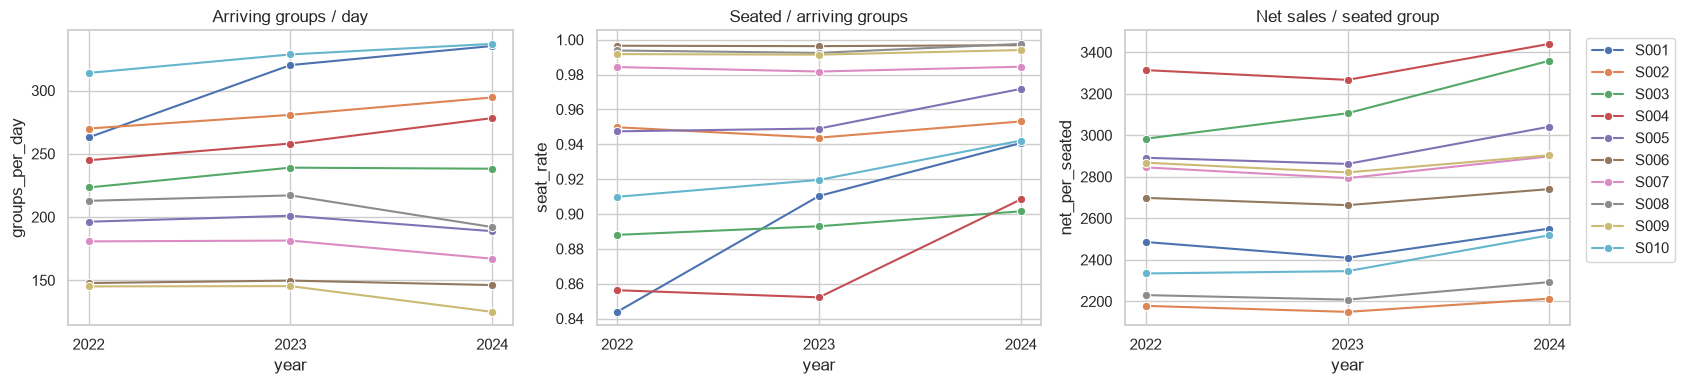

In [3]:
yearly=monthly.groupby(['store_id','year'],observed=True)[['groups','seated','left','guests','net','days']].sum().reset_index().merge(stores,on='store_id',validate='many_to_one')
yearly['groups_per_day']=yearly.groups/yearly.days
yearly['seat_rate']=yearly.seated/yearly.groups
yearly['net_per_seated']=yearly.net/yearly.seated
yearly['net_per_day']=yearly.net/yearly.days
assert np.allclose(yearly.groups_per_day*yearly.seat_rate*yearly.net_per_seated,yearly.net_per_day)
display(yearly[['store_id','area_type','year','groups_per_day','seat_rate','net_per_seated','net_per_day']].sort_values(['store_id','year']))
fig,ax=plt.subplots(1,3,figsize=(17,4));
for a,col,title in zip(ax,['groups_per_day','seat_rate','net_per_seated'],['Arriving groups / day','Seated / arriving groups','Net sales / seated group']):
    sns.lineplot(data=yearly,x='year',y=col,hue='store_id',marker='o',legend=(a is ax[2]),ax=a);a.set(title=title);a.set_xticks([2022,2023,2024])
ax[2].legend(bbox_to_anchor=(1.02,1),loc='upper left');plt.tight_layout();plt.show()

## 変化の算術分解
各要素の対数変化の割合で、売上の日次平均の差額を按分する（log-mean 方式）。3要素の寄与額は売上差額と一致する。要因が同時に変わるため、値を個別の施策による効果と解釈しない。

2023 → 2024（円/日）
2022 → 2023（円/日）


,store_id,net_per_day_before,net_per_day_after,sales_change,contribution_groups_per_day,contribution_seat_rate,contribution_net_per_seated
8,S009,"406,513.7342","360,813.3607","-45,700.3736","-57,776.5051","1,024.1647","11,051.9668"
7,S008,"475,739.4164","439,190.6202","-36,548.7962","-56,088.0187","2,380.9906","17,158.2319"
6,S007,"497,381.1890","476,623.9699","-20,757.2191","-40,049.9589","1,365.7384","17,927.0014"
5,S006,"397,295.5699","399,384.2514","2,088.6815","-9,546.1862",222.2970,"11,412.5707"
4,S005,"545,985.9205","557,918.2514","11,932.3308","-34,682.0669","13,074.3338","33,540.0639"
1,S002,"569,489.6192","621,105.8579","51,616.2387","28,431.7615","5,821.9729","17,362.5043"
2,S003,"662,897.0849","721,246.1694","58,349.0845","-2,447.5665","6,610.4591","54,186.1919"
9,S010,"708,486.4685","799,227.4536","90,740.9851","18,919.4267","18,249.8001","53,571.7583"
0,S001,"702,088.1863","804,278.2568","102,190.0705","34,702.9231","24,671.7627","42,815.3848"
3,S004,"718,475.9616","869,341.0738","150,865.1121","59,346.4779","50,564.2341","40,954.4001"


,store_id,net_per_day_before,net_per_day_after,sales_change,contribution_groups_per_day,contribution_seat_rate,contribution_net_per_seated
6,S007,"506,133.4521","497,381.1890","-8,752.2630","1,769.0742","-1,305.6472","-9,215.6900"
8,S009,"412,830.1863","406,513.7342","-6,316.4521",571.8110,-127.6210,"-6,760.6420"
5,S006,"397,451.9178","397,295.5699",-156.3479,"5,137.2003",-91.6996,"-5,201.8486"
7,S008,"471,525.8055","475,739.4164","4,213.6110","9,533.1027",-663.4799,"-4,656.0118"
4,S005,"537,702.5918","545,985.9205","8,283.3288","12,950.9708",919.9225,"-5,587.5645"
1,S002,"558,384.7315","569,489.6192","11,104.8877","22,182.8997","-3,547.6799","-7,530.3321"
3,S004,"694,795.7808","718,475.9616","23,680.1808","37,165.0489","-3,381.1164","-10,103.7518"
9,S010,"666,628.2822","708,486.4685","41,858.1863","31,300.8595","7,289.9562","3,267.3706"
2,S003,"591,670.8521","662,897.0849","71,226.2329","42,492.7339","3,472.7210","25,260.7780"
0,S001,"551,439.7918","702,088.1863","150,648.3945","122,796.4982","47,315.9711","-19,464.0748"


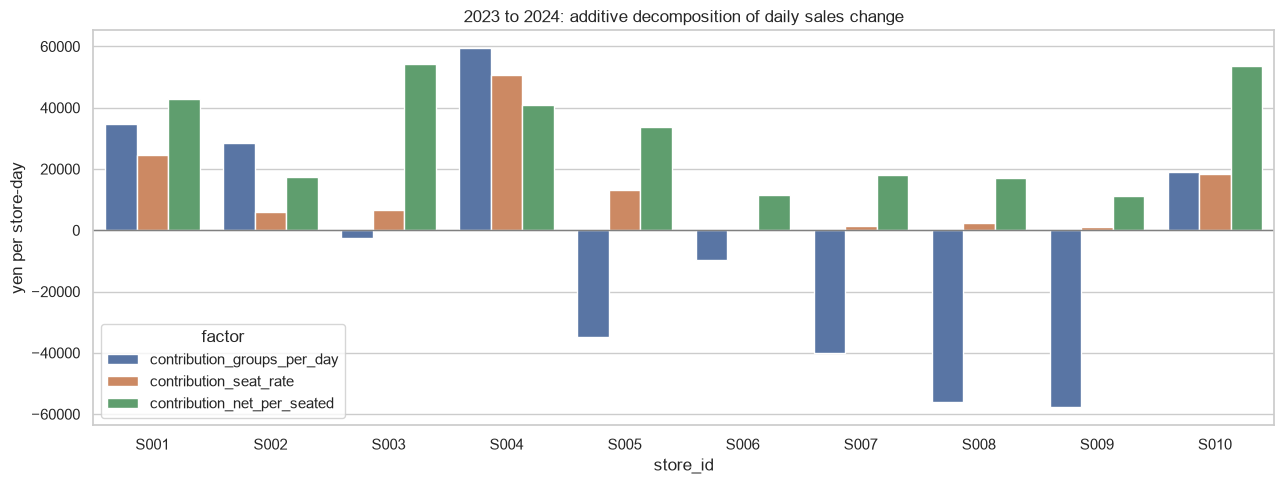

In [4]:
def decomposition(before,after,join_cols):
    fields=['groups_per_day','seat_rate','net_per_seated','net_per_day']
    x=before[join_cols+fields].merge(after[join_cols+fields],on=join_cols,suffixes=('_before','_after'),validate='one_to_one')
    factors=['groups_per_day','seat_rate','net_per_seated']
    for col in factors:
        assert (x[f'{col}_before']>0).all() and (x[f'{col}_after']>0).all()
        x[f'log_change_{col}']=np.log(x[f'{col}_after']/x[f'{col}_before'])
    x['sales_change']=x.net_per_day_after-x.net_per_day_before
    log_total=sum(x[f'log_change_{f}'] for f in factors)
    # 全体の対数変化がゼロでも各要素の寄与を取り消さず、極限値を使う。
    scale=np.empty(len(x)); close=np.isclose(log_total,0,rtol=0,atol=1e-12)
    scale[~close]=x.loc[~close,'sales_change']/log_total.loc[~close]
    scale[close]=x.loc[close,'net_per_day_before']
    for col in factors:x[f'contribution_{col}']=scale*x[f'log_change_{col}']
    x['contribution_sum']=sum(x[f'contribution_{f}'] for f in factors)
    assert np.allclose(x.sales_change,x.contribution_sum,atol=1e-7)
    return x

d23=decomposition(yearly[yearly.year.eq(2022)],yearly[yearly.year.eq(2023)],['store_id'])
d24=decomposition(yearly[yearly.year.eq(2023)],yearly[yearly.year.eq(2024)],['store_id'])
cols=['store_id','net_per_day_before','net_per_day_after','sales_change','contribution_groups_per_day','contribution_seat_rate','contribution_net_per_seated']
print('2023 → 2024（円/日）');display(d24[cols].sort_values('sales_change'))
print('2022 → 2023（円/日）');display(d23[cols].sort_values('sales_change'))
plot=d24.melt(id_vars=['store_id'],value_vars=['contribution_groups_per_day','contribution_seat_rate','contribution_net_per_seated'],var_name='factor',value_name='contribution')
fig,ax=plt.subplots(figsize=(13,5));sns.barplot(data=plot,x='store_id',y='contribution',hue='factor',ax=ax);ax.axhline(0,color='gray',lw=1);ax.set(title='2023 to 2024: additive decomposition of daily sales change',ylabel='yen per store-day');plt.tight_layout();plt.show()

## 月別の前年比・分解の安定性
前年同月の差を暦日数で補正し、3要素へ按分する。曜日・祝日の配置や価格・施策などは揃えていない。

,months,positive_months,median_change,min_change,max_change
store_id,,,,,
S001,12,12,0.1048,0.0378,0.3749
S002,12,11,0.0863,-0.0236,0.2885
S003,12,12,0.0781,0.0122,0.2052
S004,12,12,0.2317,0.0793,0.3174
S005,12,8,0.0206,-0.1310,0.1295
S006,12,7,0.0046,-0.0511,0.0572
S007,12,1,-0.0357,-0.1206,0.0007
S008,12,1,-0.0791,-0.1307,0.0144
S009,12,1,-0.1447,-0.1998,0.0318


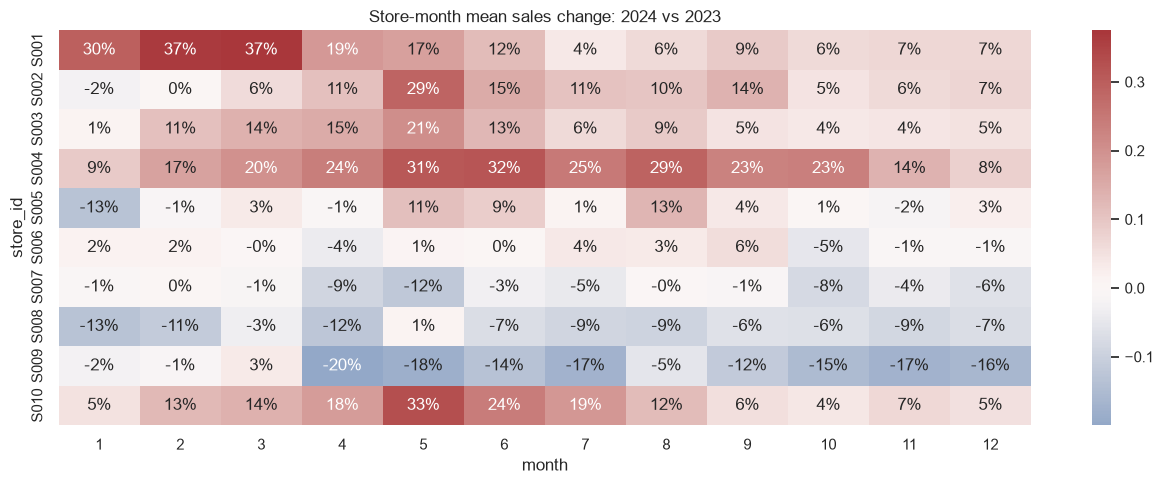

In [5]:
monthly['groups_per_day']=monthly.groups/monthly.days;monthly['seat_rate']=monthly.seated/monthly.groups;monthly['net_per_seated']=monthly.net/monthly.seated;monthly['net_per_day']=monthly.net/monthly.days
month_diff=decomposition(monthly[monthly.year.eq(2023)],monthly[monthly.year.eq(2024)],['store_id','month'])
month_diff['relative_change']=month_diff.net_per_day_after/month_diff.net_per_day_before-1
display(month_diff.groupby('store_id').agg(months=('month','size'),positive_months=('sales_change',lambda x:(x>0).sum()),median_change=('relative_change','median'),min_change=('relative_change','min'),max_change=('relative_change','max')))
fig,ax=plt.subplots(figsize=(13,5));sns.heatmap(month_diff.pivot(index='store_id',columns='month',values='relative_change').astype(float),center=0,cmap='vlag',annot=True,fmt='.0%',ax=ax);ax.set(title='Store-month mean sales change: 2024 vs 2023',xlabel='month');plt.tight_layout();plt.show()

## 客層・組人数別の構成変化
客層はログの分類。売上の単純な寄与は客層ごとの売上÷年日数の差で、来店人数や単価の影響を両方含む。

In [6]:
seg=segment.groupby(['year','segment'],observed=True)[['groups','seated','left','guests','net']].sum().reset_index()
seg['days']=seg.year.map({y:366 if pycalendar.isleap(y) else 365 for y in [2022,2023,2024]})
seg['net_per_day']=seg.net/seg.days;seg['left_rate']=seg.left/seg.groups;seg['yen_per_seated']=seg.net/seg.seated
seg23=seg[seg.year.eq(2023)].set_index('segment');seg24=seg[seg.year.eq(2024)].set_index('segment')
seg_change=pd.DataFrame({'net_per_day_2023':seg23.net_per_day,'net_per_day_2024':seg24.net_per_day,'change':seg24.net_per_day-seg23.net_per_day,'groups_2023':seg23.groups,'groups_2024':seg24.groups,'left_rate_2023':seg23.left_rate,'left_rate_2024':seg24.left_rate})
display(seg_change.sort_values('change',ascending=False))
size_totals=sizes.groupby(['year','group_size'],observed=True)[['groups','seated','left','net']].sum().reset_index();size_totals['left_rate']=size_totals.left/size_totals.groups
print('組人数別の離脱率:');display(size_totals.pivot(index='group_size',columns='year',values='left_rate'))

組人数別の離脱率:


,net_per_day_2023,net_per_day_2024,change,groups_2023,groups_2024,left_rate_2023,left_rate_2024
segment,,,,,,,
couple,"1,014,459.8521","1,151,312.0137","136,852.1616",158670,169013,0.0225,0.0157
family,"2,256,570.1041","2,357,952.4426","101,382.3385",210813,201574,0.1543,0.1234
student,"772,143.6795","816,812.3661","44,668.6867",102579,101238,0.0444,0.0333
single,"189,258.4164","226,510.7650","37,252.3486",61520,68823,0.0199,0.0082
senior,"558,097.5315","581,518.2650","23,420.7335",117805,116239,0.0124,0.0083
worker,"893,823.5671","915,023.4126","21,199.8454",195802,185653,0.0614,0.0457


year,2022,2023,2024
group_size,,,
1,0.0334,0.0211,0.0105
2,0.0344,0.0283,0.0201
3,0.1276,0.1257,0.0962
4,0.1356,0.1292,0.0970
5,0.2950,0.3145,0.2889


## 解釈の注意
- 寄与額は売上の変化を数式上分けたもので、個々の要因を操作した場合の効果ではない。
- 日割り補正では曜日・祝日・天候・キャンペーンや、店舗改装・価格変更などは補正されない。
- 離脱した組の潜在売上は観測されない。離脱件数をそのまま売上損失額に変換しない。
- 2025年の来店・着席・会計は未知。過去の年次・月次統計を使う場合は検証基準日前に計算する。